In [1]:
from google.colab import files

uploaded = files.upload()

Saving dataset-ccn_project_trafficSignrecognation.zip to dataset-ccn_project_trafficSignrecognation.zip


In [2]:
import zipfile
import os

zip_path = "/content/dataset-ccn_project_trafficSignrecognation.zip"
extract_path = "/content/traffic_sign_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset Extracted Successfully!")
print("Folders:", os.listdir(extract_path))

Dataset Extracted Successfully!
Folders: ['signnames.csv', 'Meta.csv', 'Train', 'Train.csv', 'Test.csv', 'Meta', 'Test']


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns
import os

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [4]:
DATASET_PATH = "/content/traffic_sign_dataset"

train_df = pd.read_csv(os.path.join(DATASET_PATH, "Train.csv"))
test_df = pd.read_csv(os.path.join(DATASET_PATH, "Test.csv"))
signnames_df = pd.read_csv(os.path.join(DATASET_PATH, "signnames.csv"))

print("Train Shape:", train_df.shape)
print("Test Shape:", test_df.shape)
print("Number of Classes:", train_df["ClassId"].nunique())

train_df.head()

Train Shape: (39209, 8)
Test Shape: (12630, 8)
Number of Classes: 43


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,/code/Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,/code/Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,/code/Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,/code/Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,/code/Train/20/00020_00000_00004.png


In [5]:
TRAIN_IMAGE_DIR = os.path.join(DATASET_PATH, "Train")
TEST_IMAGE_DIR = os.path.join(DATASET_PATH, "Test")

train_df["image_path"] = train_df["Path"].apply(
    lambda x: os.path.join(TRAIN_IMAGE_DIR, x.split("Train/", 1)[1])
)

test_df["image_path"] = test_df["Path"].apply(
    lambda x: os.path.join(TEST_IMAGE_DIR, x.split("Test/", 1)[1])
)

print("First Train Path:", train_df["image_path"].iloc[0])
print("First Test Path:", test_df["image_path"].iloc[0])

print("Train Image Exists:", os.path.exists(train_df["image_path"].iloc[0]))
print("Test Image Exists:", os.path.exists(test_df["image_path"].iloc[0]))

missing_train = sum(not os.path.exists(p) for p in train_df["image_path"])
missing_test = sum(not os.path.exists(p) for p in test_df["image_path"])

print("Missing Train Images:", missing_train)
print("Missing Test Images:", missing_test)

First Train Path: /content/traffic_sign_dataset/Train/20/00020_00000_00000.png
First Test Path: /content/traffic_sign_dataset/Test/00000.png
Train Image Exists: True
Test Image Exists: True
Missing Train Images: 0
Missing Test Images: 0


In [6]:
train_data, val_data = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42,
    stratify=train_df["ClassId"]
)

print("Training Samples:", len(train_data))
print("Validation Samples:", len(val_data))
print("Testing Samples:", len(test_df))

Training Samples: 31367
Validation Samples: 7842
Testing Samples: 12630


In [7]:
IMG_SIZE = 128
BATCH_SIZE = 32
NUM_CLASSES = 43
EPOCHS = 20
LEARNING_RATE = 0.001

print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Number of Classes:", NUM_CLASSES)
print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)

Image Size: 128
Batch Size: 32
Number of Classes: 43
Epochs: 20
Learning Rate: 0.001


In [8]:
def load_image(path, label):

    image = tf.io.read_file(path)
    image = tf.image.decode_png(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


def create_dataset(dataframe, shuffle=False):

    paths = dataframe["image_path"].values
    labels = dataframe["ClassId"].values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        dataset = dataset.shuffle(buffer_size=10000, seed=42)

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_dataset = create_dataset(train_data, shuffle=True)
val_dataset = create_dataset(val_data)
test_dataset = create_dataset(test_df)

print("Datasets Created Successfully!")

Datasets Created Successfully!


In [9]:
for images, labels in train_dataset.take(1):
    print("Image Batch Shape:", images.shape)
    print("Label Batch Shape:", labels.shape)

Image Batch Shape: (32, 128, 128, 3)
Label Batch Shape: (32,)


In [10]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
])

print("Data Augmentation Created Successfully!")

Data Augmentation Created Successfully!


In [11]:
model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    data_augmentation,

    # Block 1
    layers.Conv2D(32, (3,3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2,2)),

    # Block 2
    layers.Conv2D(64, (3,3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2,2)),

    # Block 3
    layers.Conv2D(128, (3,3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2,2)),

    # Block 4
    layers.Conv2D(256, (3,3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2,2)),

    # Fully Connected Layers
    layers.Flatten(),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,595,947 (17.53 MB)

 Trainable params: 4,594,987 (17.53 MB)

 Non-trainable params: 960 (3.75 KB)

In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [13]:
class MinimumEpochEarlyStopping(tf.keras.callbacks.Callback):

    def __init__(self, patience=4, min_epochs=5):
        super().__init__()

        self.patience = patience
        self.min_epochs = min_epochs
        self.best = float("inf")
        self.wait = 0
        self.best_weights = None

    def on_epoch_end(self, epoch, logs=None):

        current = logs.get("val_loss")

        if current is None:
            return

        if current < self.best:
            self.best = current
            self.wait = 0
            self.best_weights = self.model.get_weights()

        elif epoch + 1 >= self.min_epochs:
            self.wait += 1

        if epoch + 1 >= self.min_epochs and self.wait >= self.patience:
            print("Early Stopping Triggered!")
            self.model.stop_training = True

    def on_train_end(self, logs=None):

        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)


early_stopping = MinimumEpochEarlyStopping(
    patience=4,
    min_epochs=5
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

print("Callbacks Created Successfully!")

Callbacks Created Successfully!


In [15]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 54s 55ms/step - accuracy: 0.1669 - loss: 2.9526 - val_accuracy: 0.3054 - val_loss: 2.4620 - learning_rate: 0.0010
Epoch 2/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 84s 57ms/step - accuracy: 0.1703 - loss: 2.9379 - val_accuracy: 0.3166 - val_loss: 2.4337 - learning_rate: 0.0010
Epoch 3/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 82s 57ms/step - accuracy: 0.1750 - loss: 2.9170 - val_accuracy: 0.3256 - val_loss: 2.4020 - learning_rate: 0.0010
Epoch 4/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 54s 55ms/step - accuracy: 0.1766 - loss: 2.9116 - val_accuracy: 0.3270 - val_loss: 2.4157 - learning_rate: 0.0010
Epoch 5/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 55s 56ms/step - accuracy: 0.1844 - loss: 2.8745 - val_accuracy: 0.3375 - val_loss: 2.3242 - learning_rate: 0.0010
Epoch 6/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 54s 55ms/step - accuracy: 0.1781 - loss: 2.8573 - val_accuracy: 0.2984 - val_loss: 2.2818 - learning_rate: 0.0010
Epoch 7/20
981/981 ━━━━━━━━━━━━━━━━━━━━ 54s 55ms/step - accuracy: 0.1786 - l

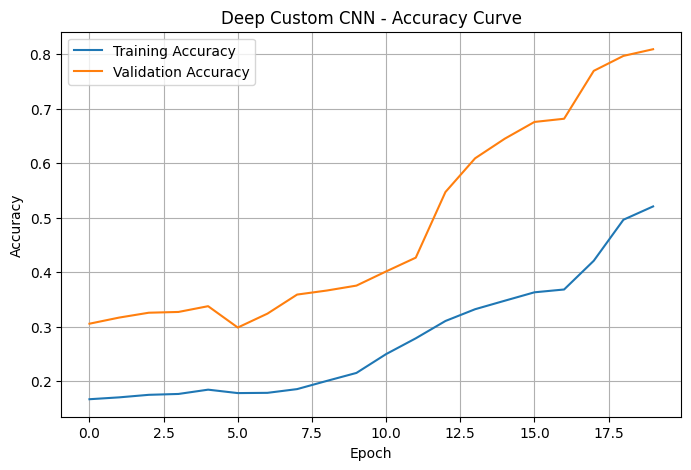

In [16]:
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Deep Custom CNN - Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

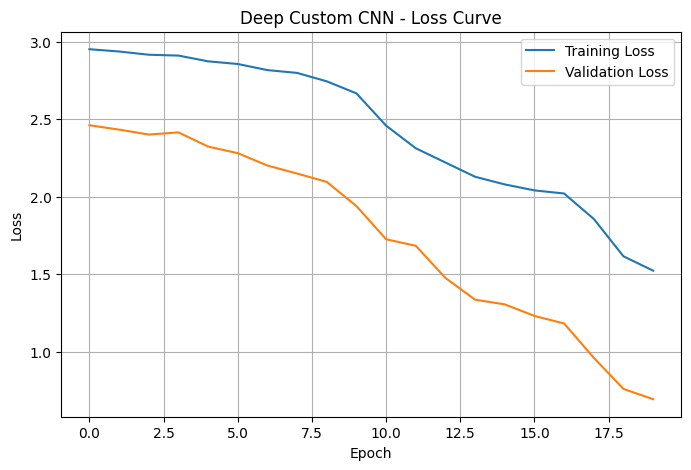

In [17]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Deep Custom CNN - Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [18]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

395/395 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.7925 - loss: 0.7676
Test Loss: 0.7675638198852539
Test Accuracy: 0.7924782037734985
Test Accuracy (%): 79.24782037734985


In [19]:
y_true = test_df["ClassId"].values

y_pred_prob = model.predict(test_dataset)

y_pred = np.argmax(y_pred_prob, axis=1)

target_names = (
    signnames_df.sort_values("ClassId")["SignName"].tolist()
)

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=target_names,
        zero_division=0
    )
)

395/395 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step
                                                    precision    recall  f1-score   support

                              Speed limit (20km/h)       0.00      0.00      0.00        60
                              Speed limit (30km/h)       0.93      0.98      0.96       720
                              Speed limit (50km/h)       0.94      0.97      0.95       750
                              Speed limit (60km/h)       0.67      0.71      0.69       450
                              Speed limit (70km/h)       0.90      0.98      0.94       660
                              Speed limit (80km/h)       0.76      0.92      0.83       630
                       End of speed limit (80km/h)       0.85      1.00      0.92       150
                             Speed limit (100km/h)       0.77      0.77      0.77       450
                             Speed limit (120km/h)       0.78      0.66      0.72       450
                                     

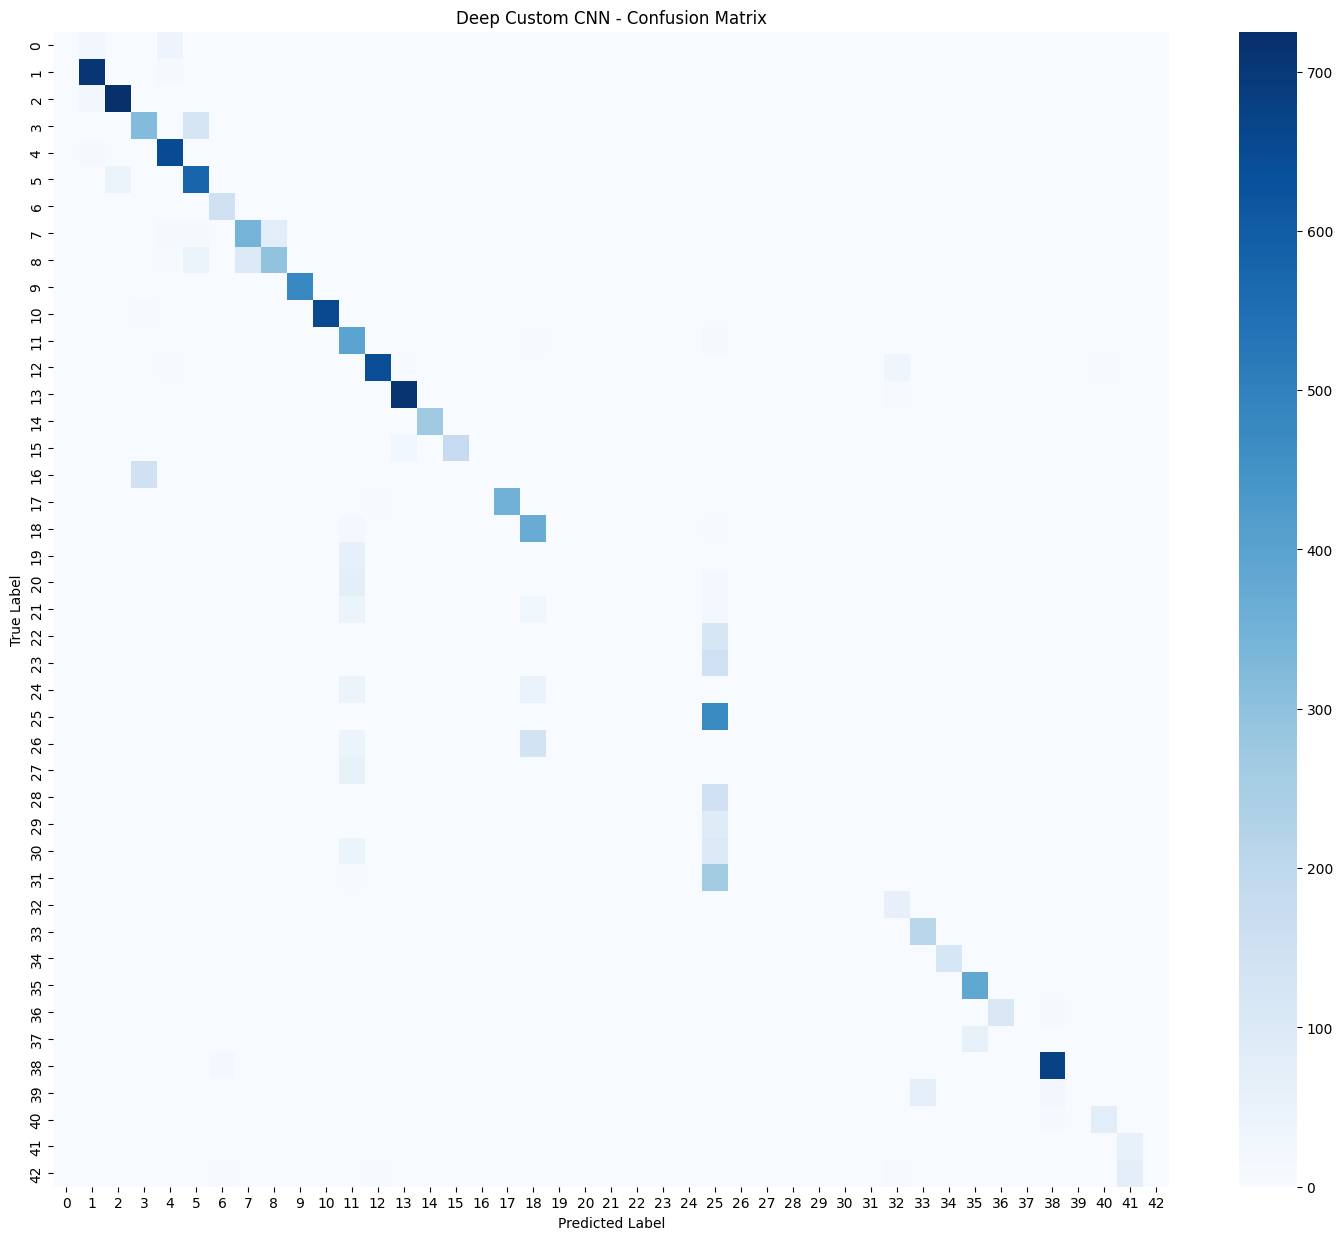

In [20]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18,15))

sns.heatmap(
    cm,
    cmap="Blues",
    annot=False,
    fmt="d"
)

plt.title("Deep Custom CNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()